# Machine Learning – Assignment 2: Classification Models and Streamlit Deployment

**Student:** Nelli Haritha | **BITS ID:** 2026AJ05411 | **Programme:** M.Tech (AIML)

**Dataset:** Breast Cancer Wisconsin (Diagnostic) – UCI Machine Learning Repository – 569 instances, 30 features, binary target.

| Assignment requirement | Section in this notebook |
|---|---|
| Step 1 – Dataset choice (≥ 12 features, ≥ 500 instances) | Section 1 |
| Step 2 – Implement 5 classifiers on the same dataset | Sections 2 and 3 |
| Step 2 – Accuracy, AUC, Precision, Recall, F1, MCC for each model | Section 4 |
| Confusion matrices / error analysis | Sections 5 and 6 |
| Step 5d – Comparison table | Section 7 |
| Step 5d – Observations and overall winner | Section 8 |
| Step 3 – Repository files (`model/`, `test_data.csv`) | Section 9 |
| Step 4 and Step 6 – `requirements.txt` and Streamlit app | Section 10 |
| Submission PDF and final checklist | Section 11 |

In [11]:
# ---------------------------------------------------------------
# Setup: import every library used in this assignment
# ---------------------------------------------------------------
import json                      # write metadata.json
import subprocess                # run the PDF builder script
import sys                       # path of the current Python interpreter
from pathlib import Path         # OS-independent file paths

import joblib                    # save / load trained models (.joblib files)
import matplotlib.pyplot as plt  # plotting
import pandas as pd              # tabular data handling
import seaborn as sns            # confusion-matrix heatmaps

# Dataset (UCI Breast Cancer Wisconsin Diagnostic, shipped with scikit-learn)
from sklearn.datasets import load_breast_cancer

# The five classifiers required by the assignment
from sklearn.linear_model import LogisticRegression    # 1. Logistic Regression
from sklearn.tree import DecisionTreeClassifier        # 2. Decision Tree
from sklearn.neighbors import KNeighborsClassifier     # 3. K-Nearest Neighbour
from sklearn.naive_bayes import GaussianNB             # 4. Naive Bayes (Gaussian)
from sklearn.svm import SVC                            # 5. Support Vector Machine

# The six evaluation metrics required by the assignment
from sklearn.metrics import (
    accuracy_score,      # 1. Accuracy
    roc_auc_score,       # 2. AUC score
    precision_score,     # 3. Precision
    recall_score,        # 4. Recall
    f1_score,            # 5. F1 score
    matthews_corrcoef,   # 6. Matthews Correlation Coefficient (MCC)
    confusion_matrix,    # used for the confusion matrices / error analysis
)

# Preprocessing and data-splitting utilities
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Project folders: models are saved in model/ so the Streamlit app can load them
ROOT = Path.cwd()
MODEL_DIR = ROOT / "model"
MODEL_DIR.mkdir(exist_ok=True)

# Fixed random seed so every run gives exactly the same split and results
RANDOM_STATE = 2026
print("Working folder:", ROOT)

Working folder: /Users/nharitha/Downloads/ML_Assignment_2_2026AJ05411


## 1. Step 1 – Dataset choice

**Question:** Choose ONE public classification dataset (Kaggle or UCI) with at least 12 features and 500 instances.

**Answer – chosen dataset: Breast Cancer Wisconsin (Diagnostic)**

| Item | Details |
|---|---|
| Public URL (UCI – primary source) | https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic |
| Public URL (Kaggle mirror) | https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data |
| Creators | Dr. William H. Wolberg, W. Nick Street, Olvi L. Mangasarian – University of Wisconsin (1995) |
| How it is loaded here | `sklearn.datasets.load_breast_cancer()` – scikit-learn ships an exact copy of the UCI data |

| Property | Value | Requirement met? |
|---|---|---|
| Instances | 569 | Yes – ≥ 500 |
| Features | 30 numeric (real-valued) features | Yes – ≥ 12 |
| Problem type | Binary classification | Yes – binary or multi-class allowed |
| Target | `0 = malignant` (212), `1 = benign` (357) | – |
| Missing values | None | – |

**Feature description:** the features are computed from a digitised image of a fine-needle aspirate (FNA) of a breast mass and describe the cell nuclei in the image. Ten properties are measured for each nucleus: radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, and fractal dimension. For each property the dataset gives the **mean**, the **standard error**, and the **worst** (mean of the three largest) value, giving 10 × 3 = 30 features.

**Task:** predict whether a tumour is malignant or benign from these 30 measurements.

In [12]:
# ---------------------------------------------------------------
# Step 1: load the dataset and verify the assignment's size rules
# ---------------------------------------------------------------
dataset = load_breast_cancer(as_frame=True)   # returns pandas objects
features = dataset.data.copy()                 # X: 30 numeric input features
target = dataset.target.rename("target")       # y: 0 = malignant, 1 = benign

# Check the minimum dataset size required by the assignment
n_instances, n_features = features.shape
assert n_instances >= 500, "Assignment needs at least 500 instances"
assert n_features >= 12, "Assignment needs at least 12 features"
print(f"Instances: {n_instances} (>= 500)  |  Features: {n_features} (>= 12)")

# Check there are no missing values (so no imputation step is needed)
print("Missing values:", int(features.isna().sum().sum()))

# Class balance: 0 = malignant, 1 = benign
print("\nClass counts:")
print(target.value_counts().rename({0: "0 = malignant", 1: "1 = benign"}))

# Preview the first five rows
features.head()

Instances: 569 (>= 500)  |  Features: 30 (>= 12)
Missing values: 0

Class counts:
target
1 = benign       357
0 = malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Train / test split

The data is split **80% training / 20% testing** with `stratify=target`, so both sets keep the same malignant/benign ratio. The 20% test set (114 rows) is never used for training. It is saved as `test_data.csv`, which the Streamlit app evaluates.

In [13]:
# ---------------------------------------------------------------
# Split into training (80%) and testing (20%) sets
# ---------------------------------------------------------------
x_train, x_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.20,             # 20% of rows held out for testing
    stratify=target,            # keep the malignant/benign ratio in both sets
    random_state=RANDOM_STATE,  # reproducible split
)

print("Train rows:", len(x_train), "| Test rows:", len(x_test))
print("Test set class counts:", y_test.value_counts().to_dict())

Train rows: 455 | Test rows: 114
Test set class counts: {1: 72, 0: 42}


## 3. Step 2 – Implement the five classification models

**Question:** Implement Logistic Regression, Decision Tree, KNN, Naive Bayes, and SVM on the same dataset.

**Answer:** All five models are trained on the same 455 training rows and evaluated on the same 114 test rows.

| # | Model | Configuration | Why this configuration |
|---|---|---|---|
| 1 | Logistic Regression | `StandardScaler` + `LogisticRegression(max_iter=3000)` | Scaling helps the solver converge; it is a linear baseline |
| 2 | Decision Tree | `DecisionTreeClassifier(max_depth=5)` | Limiting depth reduces overfitting; trees do not need scaling |
| 3 | K-Nearest Neighbour | `StandardScaler` + `KNeighborsClassifier(n_neighbors=7)` | KNN uses distances, so features must be on the same scale |
| 4 | Naive Bayes | `StandardScaler` + `GaussianNB()` | Gaussian NB suits continuous numeric features |
| 5 | Support Vector Machine | `StandardScaler` + `SVC(kernel="rbf", probability=True)` | RBF kernel learns a non-linear boundary; `probability=True` gives scores for AUC |

The scaler sits **inside** each `Pipeline`. It is therefore fitted only on training data and saved together with the model, so the Streamlit app needs no separate preprocessing file.

In [14]:
# ---------------------------------------------------------------
# Step 2: define the five required classifiers
# ---------------------------------------------------------------
models = {
    # 1. Logistic Regression: linear model; scaling helps convergence
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    ]),
    # 2. Decision Tree: rule-based, scale-invariant; depth 5 limits overfitting
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    # 3. KNN: distance-based, so features must be standardised
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=7)),
    ]),
    # 4. Gaussian Naive Bayes: assumes features are independent and normally distributed
    "Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB()),
    ]),
    # 5. SVM with RBF kernel; probability=True enables predict_proba for AUC
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
    ]),
}
print("Models defined:", list(models))

Models defined: ['Logistic Regression', 'Decision Tree', 'KNN', 'Naive Bayes', 'Support Vector Machine']


## 4. Step 2 – Train, save, and evaluate each model

**Question:** For each model, calculate Accuracy, AUC, Precision, Recall, F1, and MCC.

The positive class is `1 = benign`. TP, TN, FP, and FN are counts from the confusion matrix.

| Metric | Formula / meaning |
|---|---|
| Accuracy | (TP + TN) / total – share of correct predictions |
| AUC | Area under the ROC curve, from predicted probabilities – how well the model ranks positives above negatives (1.0 = perfect) |
| Precision | TP / (TP + FP) – of rows predicted benign, the share that really are benign |
| Recall | TP / (TP + FN) – of truly benign rows, the share found |
| F1 | 2 · Precision · Recall / (Precision + Recall) – harmonic mean of precision and recall |
| MCC | (TP·TN − FP·FN) / √((TP+FP)(TP+FN)(TN+FP)(TN+FN)) – balanced score from −1 to +1, reliable when classes are imbalanced |

Each trained model is saved to `model/<name>.joblib` for the Streamlit app.

In [15]:
# ---------------------------------------------------------------
# Step 2: train each model, save it, and compute the six metrics
# ---------------------------------------------------------------
def evaluate_model(model, x, y):
    """Return predictions and the six required metrics for one fitted model."""
    predictions = model.predict(x)              # hard class labels (0 / 1)
    scores = model.predict_proba(x)[:, 1]       # probability of class 1, needed for AUC
    return predictions, {
        "Accuracy": accuracy_score(y, predictions),
        "AUC": roc_auc_score(y, scores),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "F1": f1_score(y, predictions, zero_division=0),
        "MCC": matthews_corrcoef(y, predictions),
    }


metrics, all_predictions = {}, {}
for name, model in models.items():
    model.fit(x_train, y_train)                                    # train on training data only
    file_name = f"{name.lower().replace(' ', '_')}.joblib"         # e.g. logistic_regression.joblib
    joblib.dump(model, MODEL_DIR / file_name)                      # save for the Streamlit app
    all_predictions[name], metrics[name] = evaluate_model(model, x_test, y_test)  # test-set metrics

# Comparison table in the layout required by the assignment
metrics_frame = pd.DataFrame(metrics).T
metrics_frame.index.name = "ML Model Name"
metrics_frame.round(4)

/Users/nharitha/.venvs/jupyter/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9737,0.9927,0.9726,0.9861,0.9793,0.9433
Decision Tree,0.9298,0.9395,0.9848,0.9028,0.9420,0.8588
KNN,0.9649,0.9936,0.9595,0.9861,0.9726,0.9245
Naive Bayes,0.9211,0.9848,0.9565,0.9167,0.9362,0.8341
Support Vector Machine,0.9649,0.9954,0.9857,0.9583,0.9718,0.9260


## 5. Confusion matrices

Rows show the true label and columns show the predicted label, with `0 = malignant` and `1 = benign`. The top-right cell counts **malignant tumours predicted as benign** (missed cancers). This is the most serious error in this medical problem.

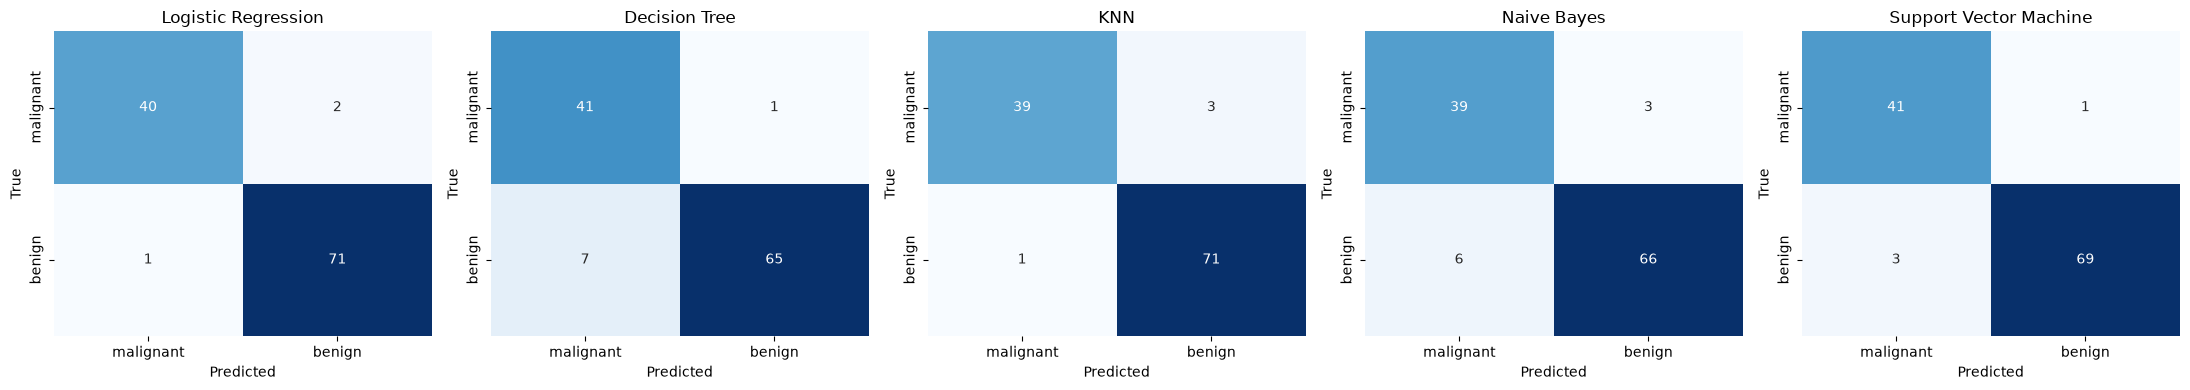

In [16]:
# ---------------------------------------------------------------
# Plot one confusion matrix per model, side by side
# ---------------------------------------------------------------
figure, axes = plt.subplots(1, 5, figsize=(22, 4))
for axis, (name, predictions) in zip(axes, all_predictions.items()):
    matrix = confusion_matrix(y_test, predictions)    # [[TN, FP], [FN, TP]] with 1 = benign
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis,
                xticklabels=["malignant", "benign"], yticklabels=["malignant", "benign"])
    axis.set_title(name)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("True")
plt.tight_layout()
plt.show()

## 6. Error analysis

The table counts each model's two error types on the 114 test rows (42 malignant, 72 benign):
- **Missed malignant (FP):** a malignant tumour predicted as benign. This is the most dangerous error.
- **False alarm (FN):** a benign tumour predicted as malignant.

In [17]:
# ---------------------------------------------------------------
# Count each type of error per model (positive class 1 = benign)
# ---------------------------------------------------------------
error_rows = {}
for name, predictions in all_predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()
    error_rows[name] = {
        "Correct": tn + tp,
        "Missed malignant (FP)": fp,   # malignant predicted as benign
        "False alarm (FN)": fn,        # benign predicted as malignant
        "Total errors": fp + fn,
    }
error_frame = pd.DataFrame(error_rows).T
error_frame

,Correct,Missed malignant (FP),False alarm (FN),Total errors
Logistic Regression,111,2,1,3
Decision Tree,106,1,7,8
KNN,110,3,1,4
Naive Bayes,105,3,6,9
Support Vector Machine,110,1,3,4


## 7. Step 5d – Comparison table

**Question:** Make a comparison table with the evaluation metrics for all 5 models.

The next cell prints the table and the best model for each metric.

In [18]:
# ---------------------------------------------------------------
# Step 5d: comparison table of all metrics for all five models
# ---------------------------------------------------------------
print(metrics_frame.round(4).to_string())   # same values as the README table

# Best model for each metric (ties are listed together)
print("\nBest model per metric:")
for metric in metrics_frame.columns:
    best_value = metrics_frame[metric].max()
    winners = metrics_frame.index[metrics_frame[metric].round(6) == round(best_value, 6)]
    print(f"  {metric:<9} {best_value:.4f}  ->  {', '.join(winners)}")

                        Accuracy     AUC  Precision  Recall      F1     MCC
ML Model Name                                                              
Logistic Regression       0.9737  0.9927     0.9726  0.9861  0.9793  0.9433
Decision Tree             0.9298  0.9395     0.9848  0.9028  0.9420  0.8588
KNN                       0.9649  0.9936     0.9595  0.9861  0.9726  0.9245
Naive Bayes               0.9211  0.9848     0.9565  0.9167  0.9362  0.8341
Support Vector Machine    0.9649  0.9954     0.9857  0.9583  0.9718  0.9260

Best model per metric:
  Accuracy  0.9737  ->  Logistic Regression
  AUC       0.9954  ->  Support Vector Machine
  Precision 0.9857  ->  Support Vector Machine
  Recall    0.9861  ->  Logistic Regression, KNN
  F1        0.9793  ->  Logistic Regression
  MCC       0.9433  ->  Logistic Regression


### Comparison table (test set, 114 rows; positive class = benign)

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | **0.9737** | 0.9927 | 0.9726 | **0.9861** | **0.9793** | **0.9433** |
| Decision Tree | 0.9298 | 0.9395 | 0.9848 | 0.9028 | 0.9420 | 0.8588 |
| KNN | 0.9649 | 0.9936 | 0.9595 | **0.9861** | 0.9726 | 0.9245 |
| Naive Bayes | 0.9211 | 0.9848 | 0.9565 | 0.9167 | 0.9362 | 0.8341 |
| Support Vector Machine | 0.9649 | **0.9954** | **0.9857** | 0.9583 | 0.9718 | 0.9260 |

Bold marks the best value in each column.

## 8. Step 5d – Observations on each model

**Question:** Add your observations on the performance of each model on the chosen dataset, and state the overall winner.

| ML Model Name | Observation about model performance |
|---|---|
| **Logistic Regression** | Best overall: 111 of 114 correct, with only 3 errors (2 missed malignant, 1 false alarm). It has the highest Accuracy (0.9737), F1 (0.9793), and MCC (0.9433), and ties KNN for the best Recall (0.9861). Its AUC (0.9927) is only slightly below SVM and KNN. After scaling, the two classes are almost linearly separable, so a simple linear boundary works very well. |
| **Decision Tree** | 106 correct, 8 errors. It misses only 1 malignant tumour, but it labels 7 benign tumours as malignant, which gives it the lowest Recall (0.9028). Its AUC (0.9395) is the lowest because a depth-5 tree outputs only a few distinct leaf probabilities, which ranks cases poorly. It is the easiest model to interpret, but its single axis-aligned splits generalise less well than the other models. |
| **KNN** | 110 correct, 4 errors (3 missed malignant, 1 false alarm). It ties for the best Recall (0.9861) and has the second-best AUC (0.9936). However, it misses more malignant cases than Logistic Regression, SVM, or Decision Tree, so its Precision (0.9595) is lower. It only works well because the features are standardised: without scaling, large-valued features such as area would dominate the distance calculation. |
| **Naive Bayes** | Weakest model: 105 correct, 9 errors (3 missed malignant, 6 false alarms), with the lowest Accuracy (0.9211) and MCC (0.8341). It assumes the features are independent, but many are strongly related (radius, perimeter, and area describe the same cell size). This distorts its probabilities. Its AUC (0.9848) is still high, so it ranks cases reasonably well, but its 0.5 decision threshold produces more errors. |
| **Support Vector Machine** | 110 correct, 4 errors (1 missed malignant, 3 false alarms). It has the highest AUC (0.9954) and the highest Precision (0.9857), and ties KNN on Accuracy (0.9649). The RBF kernel separates the classes well and ranks cases best. It misses the fewest malignant tumours (1, tied with Decision Tree) with far fewer total errors than Decision Tree, so it is the safest choice if missing a cancer matters most. |
| **Overall winner** | **Logistic Regression.** It makes the fewest total errors (3) and leads on Accuracy, F1, and MCC. MCC is the most balanced single measure for this imbalanced dataset (42 malignant vs 72 benign in the test set). It is also simple, fast, and interpretable. SVM is a close second: it ranks cases best (AUC 0.9954) and misses the fewest malignant tumours. |

## 9. Step 3 – Save repository artifacts

**Question:** The GitHub repository must contain `app.py`, `requirements.txt`, `README.md`, `test_data.csv`, and `model/` with all five saved models.

The next cell writes `test_data.csv` (the 114 held-out rows plus the `target` column) and the metric files. It then checks that every required file exists. The five `.joblib` models were already saved in Section 4.

In [19]:
# ---------------------------------------------------------------
# Step 3: save test data and metrics used by the Streamlit app
# ---------------------------------------------------------------
# test_data.csv = 30 feature columns + target (the file uploaded to the app)
test_data = x_test.copy()
test_data["target"] = y_test
test_data.to_csv(ROOT / "test_data.csv", index=False)

# Metrics files (same numbers as the comparison table)
metrics_frame.to_csv(ROOT / "metrics.csv")
metrics_frame.round(4).to_json(ROOT / "metrics.json", orient="index", indent=2)

# Dataset metadata: documents the features and the split settings
metadata = {
    "dataset": "Breast Cancer Wisconsin Diagnostic",
    "dataset_source": "scikit-learn copy of the UCI Breast Cancer Wisconsin Diagnostic dataset",
    "instances": int(features.shape[0]),
    "features": int(features.shape[1]),
    "target_column": "target",
    "classes": {"0": "malignant", "1": "benign"},
    "test_size": 0.20,
    "random_state": RANDOM_STATE,
    "feature_columns": list(features.columns),
}
(ROOT / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

# Check every file required by the assignment's repository structure
required = ["app.py", "requirements.txt", "README.md", "test_data.csv",
            "model/logistic_regression.joblib", "model/decision_tree.joblib", "model/knn.joblib",
            "model/naive_bayes.joblib", "model/support_vector_machine.joblib"]
for file_name in required:
    print(("OK      " if (ROOT / file_name).exists() else "MISSING ") + file_name)
print("\ntest_data.csv rows:", len(test_data), "| columns:", test_data.shape[1])

OK      app.py
OK      requirements.txt
OK      README.md
OK      test_data.csv
OK      model/logistic_regression.joblib
OK      model/decision_tree.joblib
OK      model/knn.joblib
OK      model/naive_bayes.joblib
OK      model/support_vector_machine.joblib

test_data.csv rows: 114 | columns: 31


## 10. Step 4 and Step 6 – requirements.txt and Streamlit app

**Step 4 answer:** `requirements.txt` pins the exact library versions used to train the models:
```
streamlit==1.66.1
scikit-learn==1.9.1
numpy==2.5.4
pandas==3.1.0
matplotlib==3.11.2
seaborn==0.13.2
joblib==1.6.0
```
Pinning scikit-learn matters: a model saved with one version may not load correctly in another.

**Step 6 answer:** `app.py` provides every required feature:

| Required feature | How `app.py` provides it |
|---|---|
| a. Dataset upload (CSV) | Sidebar `st.file_uploader` (defaults to the included `test_data.csv`) |
| b. Model selection dropdown | Sidebar `st.selectbox` listing the five models |
| c. Evaluation metrics | Six `st.metric` cards: Accuracy, AUC, Precision, Recall, F1, MCC |
| d. Confusion matrix / classification report | Both are shown, plus a table comparing all five models |

The app only **loads** the saved `.joblib` files and calls `predict` / `predict_proba`. It never retrains on uploaded data. The next cell checks this by reloading each saved model from disk and confirming it reproduces the metrics above.

In [20]:
# ---------------------------------------------------------------
# Simulate the Streamlit app: load saved models + test_data.csv,
# predict only (no fitting), and compare with the notebook metrics
# ---------------------------------------------------------------
uploaded = pd.read_csv(ROOT / "test_data.csv")          # what a user would upload
x_uploaded = uploaded.drop(columns=["target"])
y_uploaded = uploaded["target"]

for name in models:
    saved_model = joblib.load(MODEL_DIR / f"{name.lower().replace(' ', '_')}.joblib")
    _, reloaded = evaluate_model(saved_model, x_uploaded, y_uploaded)   # no .fit() call
    same = all(abs(reloaded[m] - metrics[name][m]) < 1e-12 for m in reloaded)
    print(f"{name:<24} reloaded metrics match: {same}")

Logistic Regression      reloaded metrics match: True
Decision Tree            reloaded metrics match: True
KNN                      reloaded metrics match: True
Naive Bayes              reloaded metrics match: True
Support Vector Machine   reloaded metrics match: True


## 11. Submission PDF and final checklist

| Item | Link |
|---|---|
| GitHub repository | https://github.com/nelliharitha123-source/ML_Assignment_2_2026AJ05411 |
| Live Streamlit app | https://mlassignment22026aj05411.streamlit.app/ |
